# Rebuilding my RAG with LangChain
**Shamak Patel · IT7075 Applied AI for Cybersecurity · Mini Project: Rebuild Your RAG with LangChain**

In the RAG module I built a question-and-answer bot by hand over NIST and CISA guidance on passwords and
multifactor authentication (`../rag_project/`). This notebook builds the same bot a second time with LangChain,
on the same five documents and the same eight questions, and measures it the same way.

| Part | What happens | Data |
|---|---|---|
| 1-5 | The course pipeline with the five TODOs filled in: load and split, vector store, retriever, prompt template, LCEL chain | `course_kb/ai_framework_kb.md` |
| 6-7 | The course measurements (given code, no TODO) | `framework_goldset.json` |
| 8 | My RAG rebuilt with LangChain: loader, splitter, Chroma, retriever, prompt template, chain | `my_kb/`, `goldset.json` |
| 9 | Transcript: the bot answers all eight questions, including the two it should refuse | `my_kb/` |
| 10 | The same two measurements, one setting at a time, saved as `results_langchain.csv` | `my_kb/` |
| 11 | Side by side with the RAG module, including a like-for-like row | `../rag_project/results.csv` |
| 12 | One question this version got wrong, and what the framework hides | `my_kb/` |

**Topic:** password rules and MFA, from NIST SP 800-63B-4 and two CISA fact sheets. Everything runs offline on
the small `all-MiniLM-L6-v2` embedding model: no API key, no GPU. If a working `OPENAI_API_KEY` is set (in `.env`,
never in this notebook), the model stage of the chain calls `gpt-4o-mini`; without one, an offline stand-in fills
that stage.

**To run:** `pip install -r requirements.txt`, then run all cells from the top, from inside this folder.
Restart the kernel before running again (Part 2 explains why).

# Mini-Project 3 — A Framework RAG with LangChain
### IT7075: Applied AI for Cybersecurity · LangChain

In Mini-Project 2 you built RAG **by hand**: your own chunker, your own Chroma calls, your own
prompt assembly, your own retrieve-then-generate function. Now you build the same thing **with
LangChain**, and the point of the exercise is to see exactly which parts the framework takes over.

Five pieces are left for you to write, one per stage of the pipeline in the langchain_rag notebook:

| | Stage | You write |
|---|---|---|
| **TODO 1** | load the documents and split them | 3 lines |
| **TODO 2** | build the Chroma vector store | 1 line |
| **TODO 3** | turn it into a retriever (`k` + score threshold) | 2 lines |
| **TODO 4** | write the prompt template | 2 lines |
| **TODO 5** | wire the LCEL chain together with `\|` | 3 lines |

Find them by searching for `###################`:

```
###################  TODO n — title  ###################
# what to do, and how
################
```

> **Runs offline.** Embeddings are the local `all-MiniLM-L6-v2` model, so retrieval never needs an
> API key. If you have a working `OPENAI_API_KEY` the last stage of the chain calls a real model;
> if you don't — or it is out of credit — the notebook substitutes an offline answer and keeps
> going. Everything you are graded on works either way.

## Part 1 — Load and split the documents  ·  **TODO 1**

LangChain's loaders return **`Document` objects** (text plus metadata), not plain strings — that is
the first difference from Mini-Project 2. The splitter then works on documents and hands back more
documents, carrying the metadata along for you.

> **Expected output:** `1 document -> 10 chunks`.

In [1]:
# If needed: !pip install -q langchain langchain-community langchain-chroma langchain-huggingface langchain-openai
import json, os, warnings
import pandas as pd

# Keep this notebook on the CPU. The models here are tiny (milliseconds either way),
# and this avoids the "CUDA error: no kernel image is available" failure -- or a very
# long hang while torch initialises -- on a machine whose PyTorch build does not match
# its GPU. This must run BEFORE anything imports torch.
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "")
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")   # no progress-bar widgets in the saved notebook
os.environ.setdefault("HF_HUB_VERBOSITY", "error")          # no "unauthenticated requests" notice either

# Two noisy-but-harmless warnings, silenced so the output stays readable:
#  * langchain-community is being retired (TextLoader still works and is what the langchain_rag notebook uses)
#  * LangChain warns when a relevance score falls outside 0-1. With these embeddings an
#    UNRELATED question scores slightly below 0 -- which is the behaviour we want. See Part 3.
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", message="Relevance scores must be between")

# LangChain also logs "No relevant docs were retrieved..." every time the threshold
# rejects everything. That is the behaviour we are measuring, and the cells below
# already report it as "retrieved 0 chunk(s)", so we log it once instead of 20 times.
import logging
logging.getLogger("langchain_core.vectorstores.base").setLevel(logging.ERROR)
logging.getLogger("torch.distributed.elastic.multiprocessing.redirects").setLevel(logging.ERROR)  # a macOS-only notice
from langchain_community.document_loaders import TextLoader
from langchain_text_splitters import CharacterTextSplitter

# ---- the knowledge base and question set that came with the course -------
# In my repository the course knowledge base is copied to course_kb/.
def course_path(name, folders=("course_kb/", "../../code/", "../../../code/", "./")):
    for f in folders:
        if os.path.exists(f + name):
            return f + name
    return name

KB_FILE = course_path("ai_framework_kb.md")
GOLDSET_FILE = ("framework_goldset.json" if os.path.exists("framework_goldset.json")
                else "../framework_goldset.json")


###################  TODO 1 — load the file and split it into chunks  ###################
# WHAT: load KB_FILE into `documents`, then split it into `chunks`.
#
# HOW (the "Load & Split" cell in the langchain_rag notebook):
#   * loader    = TextLoader(KB_FILE, encoding="utf-8")
#   * documents = loader.load()
#         -> a LIST of Document objects. A whole .md file loads as ONE document,
#            so len(documents) is 1. The text is in documents[0].page_content.
#   * splitter  = CharacterTextSplitter(chunk_size=900, chunk_overlap=150,
#                                       separator="\n")      <- given below
#   * chunks    = splitter.split_documents(documents)
#         -> note split_documentS: it takes Documents and returns Documents,
#            keeping the metadata. (split_text() would take a plain string.)
#
# WHY separator="\n": the splitter tries to break on that separator first, so
# chunks end at line boundaries instead of mid-sentence like in Mini-Project 2.
################

loader = TextLoader(KB_FILE, encoding="utf-8")                                 # <<< 1 line
documents = loader.load()                                                       # <<< 1 line
splitter = CharacterTextSplitter(chunk_size=900, chunk_overlap=150, separator="\n")
chunks = splitter.split_documents(documents)                                    # <<< 1 line

print(len(documents), "document ->", len(chunks), "chunks")
print("\nFirst chunk:\n", chunks[0].page_content[:200], "...")
print("\nIts metadata:", chunks[0].metadata)

1 document -> 10 chunks

First chunk:
 # NIST AI Risk Management Framework (AI RMF)
The NIST AI Risk Management Framework (AI RMF 1.0) is a voluntary framework to help organizations manage risks across the AI lifecycle. It is organized aro ...

Its metadata: {'source': 'course_kb/ai_framework_kb.md'}


## Part 2 — Build the vector store  ·  **TODO 2**

In Mini-Project 2 this took three steps: embed the chunks, create a collection, then add ids,
documents, embeddings and metadata. LangChain does all of it in **one call** — `Chroma.from_documents`
embeds and stores in a single line. That is the framework's whole pitch.

We use the **local** embedding model, so no API key is needed.

> **Expected output:** `stored 10 chunks`.

In [2]:
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_chroma import Chroma

# The offline embedding model the langchain_rag notebook names in its comment.
# Swap in OpenAIEmbeddings(model="text-embedding-3-small") if you have a working key.
embeddings = HuggingFaceEmbeddings(model_name="all-MiniLM-L6-v2")


###################  TODO 2 — put the chunks into Chroma  ###################
# WHAT: build the vector store in ONE line.
#
# HOW (the "Embed & Store" cell in the langchain_rag notebook):
#       Chroma.from_documents(<the chunks>, <the embeddings>)
#
# That single call embeds every chunk with `embeddings` and stores the vectors,
# the text, and the metadata. Compare it with Mini-Project 2, where you called
# embed() yourself and then collection.add(ids=..., documents=..., embeddings=...,
# metadatas=...). Same work; the framework hides it.
#
# NOTE: we leave out persist_directory on purpose, so the store lives in memory and
#       re-running this cell can never mix new chunks with stale ones.
################

db = Chroma.from_documents(chunks, embeddings)                     # <<< 1 line

# What I found when I re-ran this cell: with no collection_name, every from_documents() call in
# the same kernel writes into the same in-memory collection (called "langchain"), so a second run
# prints "stored 20 chunks" and the retriever returns each chunk twice. Restart the kernel before
# re-running. In Part 8 every store gets its own collection_name.

print("stored", db._collection.count(), "chunks")

stored 10 chunks


## Part 3 — Make a retriever  ·  **TODO 3**

A **retriever** is a vector store wrapped in a standard interface, so anything downstream can just
call `.invoke(question)`. It is also where your two Mini-Project 2 knobs reappear under new names:

| Mini-Project 2 (by hand) | LangChain |
|---|---|
| `k` = how many chunks | `search_kwargs={"k": ...}` |
| `max_distance` — keep hits **below** it | `score_threshold` — keep hits **above** it |

Note the flip: a **distance** is small when things are similar, but LangChain's **relevance score**
is large when things are similar. Same idea, opposite direction.

> **Expected output:** 3 chunks for the NIST question, **0** for "the capital of France" — the
> refusal you built by hand in Mini-Project 2, now handled by the retriever.

In [3]:
###################  TODO 3 — wrap the store in a retriever  ###################
# WHAT: create `retriever` from `db`, keeping at most K chunks and only those
#       scoring above THRESHOLD.
#
# HOW (the "Make a Retriever" cell in the langchain_rag notebook):
#       db.as_retriever(
#           search_type="similarity_score_threshold",
#           search_kwargs={"k": K, "score_threshold": THRESHOLD})
#
#   * search_type is the STRING "similarity_score_threshold"
#   * search_kwargs is a DICT with two keys: "k" and "score_threshold"
#
#   * search_type="similarity_score_threshold" is what makes score_threshold apply.
#     With the default search_type="similarity" the threshold is IGNORED and you
#     always get K chunks back -- the bug that made your Mini-Project 2 bot answer
#     questions its documents could not support.
#   * relevance score: HIGHER = more similar (the opposite of a distance).
#   * use the constants K and THRESHOLD below, not literal numbers -- Part 6
#     changes them.
################

K = 3
THRESHOLD = 0.3          # the langchain_rag value. Part 6 asks whether it is right.

retriever = db.as_retriever(
    search_type="similarity_score_threshold",                      # <<< 1 line
    search_kwargs={"k": K, "score_threshold": THRESHOLD})          # <<< 1 line


# ---- given: see what comes back, and what does not ----------------------
for q in ["What are the four core functions of the NIST AI Risk Management Framework?",
          "What is the capital of France?"]:
    got = retriever.invoke(q)
    print("Q:", q)
    print("   retrieved", len(got), "chunk(s)")
    for d in got:
        print("     -", d.page_content[:70].strip().replace("\n", " "), "...")
    print()

Q: What are the four core functions of the NIST AI Risk Management Framework?
   retrieved 3 chunk(s)
     - # NIST AI Risk Management Framework (AI RMF) The NIST AI Risk Manageme ...
     - # NIST Generative AI Profile The NIST AI RMF Generative AI Profile (NI ...
     - # EU AI Act The EU Artificial Intelligence Act is the first comprehens ...

Q: What is the capital of France?
   retrieved 0 chunk(s)



## Part 4 — The prompt template  ·  **TODO 4**

A `ChatPromptTemplate` is the reusable prompt from the langchain_basics notebook: you write it once with `{}`
placeholders, and the chain fills them in on every question. This replaces the string `.format()`
you did by hand in Mini-Project 2.

> **Expected output:** the filled-in prompt, showing your context in the system message and the
> question in the human message.

In [4]:
###################  TODO 4 — write the prompt template  ###################
# WHAT: build `rag_prompt` with a system message and a human message.
#
# HOW (prompt templates in langchain_basics + the chain cell in langchain_rag):
#       rag_prompt = ChatPromptTemplate.from_messages([
#           ("system", "....{context}...."),
#           ("human", "{question}"),
#       ])
#
# The system message must:
#   * tell the model to answer using ONLY the context
#   * contain the placeholder {context}
#   * say to start the reply with [RAG] when the answer is in the context, and with
#     [LLM] plus "I don't know" when it is not -- the same tagging as Mini-Project 2
# The human message is just the placeholder {question}.
#
# WATCH OUT: the two placeholder names must be exactly `context` and `question`,
#            because that is what the chain in Part 5 feeds in.
################

from langchain_core.prompts import ChatPromptTemplate

rag_prompt = ChatPromptTemplate.from_messages([
    ("system", "You are a cybersecurity assistant. Answer the question using ONLY the context "
               "below. If the answer is in the context, start your reply with [RAG]. If the "
               "context is empty or does not contain the answer, start your reply with [LLM] "
               "and say I don't know -- do not answer from memory.\n\n# Context\n{context}"),  # <<< 1 line
    ("human", "{question}"),                                                     # <<< 1 line
])

# ---- given: check what the filled-in prompt looks like ------------------
preview = rag_prompt.invoke({"context": "(pretend context here)", "question": "test question"})
for m in preview.to_messages():
    print("[%s] %s\n" % (m.type, m.content[:220]))

[system] You are a cybersecurity assistant. Answer the question using ONLY the context below. If the answer is in the context, start your reply with [RAG]. If the context is empty or does not contain the answer, start your reply 

[human] test question



## Part 5 — Wire the chain with `|`  ·  **TODO 5**

This is the part that has no equivalent in Mini-Project 2. There you wrote an `ask()` function that
called retrieve, then built the context, then called generate. In LangChain you **declare** that
flow with the pipe operator and get a single runnable object back:

```
{"context": retriever | format_docs, "question": RunnablePassthrough()}  |  prompt  |  model  |  parser
```

Read it left to right: the dict runs the retriever **and** passes the raw question through, the
prompt fills both placeholders, the model answers, and the parser turns the reply into a string.

> **Expected output:** the NIST question answered and tagged `[RAG]`; "the capital of France"
> refused and tagged `[LLM]`, because the retriever returned nothing for it.

In [5]:
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnablePassthrough, RunnableLambda


def format_docs(docs):
    """GIVEN: turn the retrieved Documents into one block of text for {context}."""
    return "\n\n".join(d.page_content for d in docs)


def offline_answer(prompt_value):
    """GIVEN: stands in for the model when no LLM is available (a RunnableLambda,
    exactly like the ones in langchain_basics). It reads the context out of the filled-in
    prompt and quotes it, so the chain still produces a tagged answer."""
    context = prompt_value.to_messages()[0].content.split("# Context", 1)[-1].strip()
    if context == "":
        return "[LLM] I don't know -- the knowledge base does not cover this. (offline mode)"
    return "[RAG] (offline mode) From the retrieved context: " + context[:220]


def build_model():
    """GIVEN: a real chat model if a working key is available, else the offline stand-in."""
    if os.getenv("OPENAI_API_KEY"):
        try:
            from langchain_openai import ChatOpenAI
            m = ChatOpenAI(model="gpt-4o-mini", temperature=0)
            m.invoke("ping")                       # fail fast if the key has no credit
            print("using ChatOpenAI(gpt-4o-mini)")
            return m | StrOutputParser()
        except Exception as e:
            print("(LLM unavailable - %s. Using offline mode.)" % type(e).__name__)
    else:
        print("(no OPENAI_API_KEY - using offline mode.)")
    return RunnableLambda(offline_answer)


model = build_model()


###################  TODO 5 — build the LCEL chain  ###################
# WHAT: assemble `rag_chain` from the four pieces you already have, using `|`.
#
# HOW (the "Build the RAG Chain (LCEL)" cell in the langchain_rag notebook):
#       rag_chain = (
#           {"context": <retriever piped into format_docs>,
#            "question": <pass the question through untouched>}
#           | <your prompt>
#           | <the model>
#       )
#
#   * the DICT is the interesting bit: both entries receive the question you invoke
#     the chain with. "context" sends it through the retriever and then through
#     format_docs; "question" passes it along untouched (RunnablePassthrough()).
#     The result is {"context": "...", "question": "..."} -- exactly the two
#     placeholders your prompt needs.
#   * `model` here already includes the output parser, so you do not add one.
#
# THEN: invoke it with just a question string -- rag_chain.invoke("...?")
################

rag_chain = (
    {"context": retriever | format_docs, "question": RunnablePassthrough()}     # <<< 1 line
    | rag_prompt                                                                 # <<< 1 line
    | model                                                                      # <<< 1 line
)

# ---- given: one question the KB answers, one it does not ----------------
for q in ["What are the four core functions of the NIST AI Risk Management Framework?",
          "What is the capital of France?"]:
    print("Q:", q)
    print("A:", rag_chain.invoke(q)[:300], "\n")

(no OPENAI_API_KEY - using offline mode.)
Q: What are the four core functions of the NIST AI Risk Management Framework?
A: [RAG] (offline mode) From the retrieved context: # NIST AI Risk Management Framework (AI RMF)
The NIST AI Risk Management Framework (AI RMF 1.0) is a voluntary framework to help organizations manage risks across the AI lifecycle. It is organized around four core functi 

Q: What is the capital of France?
A: [LLM] I don't know -- the knowledge base does not cover this. (offline mode) 



## Part 6 — Ask the bot, and measure it  *(no TODO — run it and read it)*

`framework_goldset.json` holds **8 questions** about the provided knowledge base: **6 it answers**
(each with a phrase that proves it) and **2 it does not**. The two counts are the same ones you
used in Mini-Project 2:

- **found** — of the 6, how many retrieved a chunk containing the evidence?
- **refused** — of the 2, how many correctly retrieved *nothing*?

> **Expected output at the langchain_rag settings (`k=3`, threshold 0.3): found 5/6, refused 1/2.**
> Two things go wrong at once, and neither is a bug in your code:
> **Q2** (MITRE ATLAS) finds nothing, and **Q8** — which the knowledge base cannot answer —
> gets context anyway. Part 7 shows why, and why you cannot fix both by tuning.

In [6]:
GOLDSET = json.load(open(GOLDSET_FILE))["questions"]
N_ANS = sum(q["answerable"] for q in GOLDSET)
N_UNANS = len(GOLDSET) - N_ANS


def score(retriever, goldset):
    """GIVEN: count found / refused, the same two numbers as Mini-Project 2."""
    found, refused, detail = 0, 0, []
    for q in goldset:
        docs = retriever.invoke(q["question"])
        text = " ".join(d.page_content for d in docs).lower()
        hit = any(p.lower() in text for p in q["evidence"])
        if q["answerable"]:
            found += 1 if hit else 0
        else:
            refused += 1 if len(docs) == 0 else 0
        detail.append({"qid": q["qid"], "answerable": q["answerable"],
                       "chunks": len(docs), "evidence_found": hit if q["answerable"] else "-"})
    return found, refused, detail


found, refused, detail = score(retriever, GOLDSET)
print("found   %d/%d" % (found, N_ANS))
print("refused %d/%d\n" % (refused, N_UNANS))
print(pd.DataFrame(detail).to_string(index=False))

found   5/6
refused 1/2

qid  answerable  chunks evidence_found
 Q1        True       3           True
 Q2        True       0          False
 Q3        True       2           True
 Q4        True       3           True
 Q5        True       3           True
 Q6        True       1           True
 Q7       False       0              -
 Q8       False       3              -


## Part 7 — Tune the threshold  *(no TODO)*

Sweep the threshold and watch the two counts fight each other.

> **Expected output:**
>
> | threshold | found | refused | what changed |
> |---|---:|---:|---|
> | 0.1 | **6/6** | 1/2 | finds everything, but Q8 still gets context |
> | 0.2 | **6/6** | 1/2 | same |
> | **0.3** *(lecture default)* | 5/6 | 1/2 | **worst of both** — loses Q2 *and* still leaks Q8 |
> | 0.4 | 5/6 | 1/2 | |
> | 0.5 | 5/6 | 1/2 | |
> | 0.6 | 4/6 | **2/2** | finally refuses Q8 — by giving up Q2 and Q3 too |
>
> **Read that table carefully: there is no good row.** No threshold gets 6/6 *and* 2/2, and the
> last cell shows you why — Q8, which your documents **cannot** answer, scores **0.505**, while
> Q2, which they answer perfectly well, scores only **0.258**. The wrong answer looks *more*
> relevant than the right one, so no single cut-off can separate them.
>
> That is the honest finding of this project, and it is worth more than a tidy result: **tuning
> cannot fix a ranking that is already wrong.** Fixing it would need better chunking, a better
> embedding model, or a reranking step — not a different number.
>
> Mini-Project 2 showed you the other half of this trade-off: there a *loose* threshold let the
> bot answer what it shouldn't. Both failures are silent, and only a question set catches either.

In [7]:
rows = []
for t in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6]:
    r = db.as_retriever(search_type="similarity_score_threshold",
                        search_kwargs={"k": K, "score_threshold": t})
    f, ref, _ = score(r, GOLDSET)
    rows.append({"threshold": t, "found": "%d/%d" % (f, N_ANS),
                 "refused": "%d/%d" % (ref, N_UNANS)})

results = pd.DataFrame(rows)
print(results.to_string(index=False))
# Named results_course_kb.csv in my repository, so it cannot be mistaken for results_langchain.csv
# (my own results, Part 10).
results.to_csv("results_course_kb.csv", index=False)
print("\nwrote results_course_kb.csv")

# Why is there no good row? Compare the best score for a question the KB ANSWERS
# with the best score for one it CANNOT answer.
print("\ntop-1 relevance score per question (higher = looks more relevant):")
for q in GOLDSET:
    s = db.similarity_search_with_relevance_scores(q["question"], k=1)[0][1]
    print("   %-4s %-7s %+.3f  %s" % (q["qid"], "answer" if q["answerable"] else "ABSENT",
                                      s, q["question"][:52]))
print("\nQ8 is not in the knowledge base yet outranks Q2, which is. No cut-off fixes that.")

 threshold found refused
       0.1   6/6     1/2
       0.2   6/6     1/2
       0.3   5/6     1/2
       0.4   5/6     1/2
       0.5   5/6     1/2
       0.6   4/6     2/2

wrote results_course_kb.csv

top-1 relevance score per question (higher = looks more relevant):
   Q1   answer  +0.640  What are the four core functions of the NIST AI Risk
   Q2   answer  +0.258  What is MITRE ATLAS used for?
   Q3   answer  +0.548  Name three risks from the OWASP Top 10 for LLM Appli
   Q4   answer  +0.696  What obligations does the EU AI Act place on high-ri
   Q5   answer  +0.656  What are the core elements of Google's Secure AI Fra
   Q6   answer  +0.623  What is the MAESTRO threat modeling framework used f
   Q7   ABSENT  -0.283  What is the capital of France?
   Q8   ABSENT  +0.505  What are the five core functions of the NIST Cyberse

Q8 is not in the knowledge base yet outranks Q2, which is. No cut-off fixes that.


## Part 8: rebuild your own RAG with LangChain

Everything above used the provided knowledge base, and it was practice. Now build the same system you
built in the RAG module, this time with LangChain, using the same data and the same questions.

Copy your `my_kb/` folder and your `goldset.json` from the RAG module into this project folder. Do not
change the documents or the questions: the comparison in your report depends on both systems answering
exactly the same eight questions over exactly the same text.

No code is provided from here on. Add cells below that:

1. Load your documents with a LangChain loader and split them with a text splitter.
2. Build a vector store from the chunks and wrap it in a retriever.
3. Write a prompt template and wire the chain with the pipe operator.
4. Answer your eight questions and print the transcript, including one the documents cannot answer.
5. Score the same measurements you used in the RAG module, vary one setting at a time, and save the
   results as `results_langchain.csv`.

Note as you go which of your RAG-module functions each LangChain object replaced. That list is the
heart of your report.

## Part 8: My data, unchanged

`my_kb/` and `goldset.json` are copied from `../rag_project/`, the RAG-module folder next to this one. The first
check below compares every file with its original, byte for byte, so the comparison in Part 11 is fair: both bots
see exactly the same text and answer exactly the same eight questions.

Then the five LangChain stages, with the RAG-module code each one replaces:

| Stage | LangChain object | Replaces, in `rag_project/rag_notebook.ipynb` |
|---|---|---|
| 1. load and split | `DirectoryLoader` + `CharacterTextSplitter` | the `open(...).read()` loop, `split_into_chunks()` and `load_and_chunk()` (TODO 1) |
| 2. vector store | `Chroma.from_documents(...)` | `embed()`, `build_collection()` and `collection.add(ids, documents, embeddings, metadatas)` (TODO 2) |
| 3. retriever | `db.as_retriever(search_type="similarity_score_threshold", ...)` | `retrieve()`: `collection.query(...)` plus the `if dist <= max_distance` filter (TODO 3) |
| 4. prompt template | `ChatPromptTemplate` + `format_sources()` | `MY_SYSTEM.format(context=...)` and `build_context()` (TODO 4) |
| 5. chain | `RunnableParallel`, then `assign`, then `RunnableBranch` into prompt → model → parser | `my_ask()`: retrieve, then augment, then refuse or generate |

The settings start where the RAG module ended: chunks of 600 characters with 100 of overlap, the same embedding
model, cosine distance, the 4 closest chunks, and my chosen distance threshold of 0.575, which becomes a
relevance-score threshold of 1 − 0.575 = **0.425** (8.4 shows why it is exactly that).

In [8]:
###################  YOUR RAG, REBUILT WITH LANGCHAIN  ###################
# Load your documents from my_kb/, split them, build a vector store and a
# retriever, write a prompt template, and wire the chain with the pipe.
################
import hashlib, re, textwrap
import numpy as np
from langchain_community.document_loaders import DirectoryLoader

MY_KB_DIR = "my_kb"
RAG_MODULE_DIR = "../rag_project"          # the RAG-module folder, next to this one in my repository

# ---- 8.0  the same documents and questions as the RAG module -------------
def sha256(path):
    return hashlib.sha256(open(path, "rb").read()).hexdigest()

print("Unchanged since the RAG module? (SHA-256 here vs. in %s/)" % RAG_MODULE_DIR)
for rel in sorted(os.path.join(MY_KB_DIR, f) for f in os.listdir(MY_KB_DIR) if f.endswith(".md")) + ["goldset.json"]:
    original = os.path.join(RAG_MODULE_DIR, rel)
    same = os.path.exists(original) and sha256(rel) == sha256(original)
    print("  %-46s %s...  %s" % (rel, sha256(rel)[:12], "identical" if same else "DIFFERENT OR MISSING"))


# ---- 8.1  load: replaces the open(...).read() loop -----------------------
loader = DirectoryLoader(MY_KB_DIR, glob="*.md", loader_cls=TextLoader,
                         loader_kwargs={"encoding": "utf-8"},
                         exclude=["SOURCES.md"])           # SOURCES.md lists citations, it is not knowledge
my_docs = sorted(loader.load(), key=lambda d: d.metadata["source"])   # a fixed order, so every run builds the same store
my_texts = {os.path.basename(d.metadata["source"]): d.page_content for d in my_docs}

print("\nLoaded %d Documents, %d characters:" % (len(my_docs), sum(len(t) for t in my_texts.values())))
for d in my_docs:
    print("  %-46s %5d characters   metadata=%s" % (os.path.basename(d.metadata["source"]),
                                                   len(d.page_content), d.metadata))

MY_GOLDSET = json.load(open("goldset.json"))["questions"]
n_mine_ans = sum(q["answerable"] for q in MY_GOLDSET)
n_mine_unans = len(MY_GOLDSET) - n_mine_ans
print("\nQuestions in goldset.json: %d (%d answerable, %d unanswerable)"
      % (len(MY_GOLDSET), n_mine_ans, n_mine_unans))


# ---- 8.2  split: replaces split_into_chunks() and load_and_chunk() -------
CHUNK_SIZE, OVERLAP = 600, 100                 # my RAG-module settings
my_splitter = CharacterTextSplitter(chunk_size=CHUNK_SIZE, chunk_overlap=OVERLAP,
                                    separator="\n")     # the lecture's splitter: break at line ends
my_chunks = my_splitter.split_documents(my_docs)

print("\nSplit into %d chunks (chunk_size=%d, chunk_overlap=%d, separator='\\n'):"
      % (len(my_chunks), CHUNK_SIZE, OVERLAP))
for name in my_texts:
    sizes = [len(c.page_content) for c in my_chunks if c.metadata["source"].endswith(name)]
    print("  %-46s %2d chunks, %d-%d characters" % (name, len(sizes), min(sizes), max(sizes)))

# Every evidence phrase must sit wholly inside at least one chunk; otherwise a "miss"
# would be the splitter's fault, not retrieval's.
print("\nEvidence check (is each phrase inside one chunk?):")
for q in MY_GOLDSET:
    for phrase in q["evidence"]:
        n = sum(phrase.lower() in c.page_content.lower() for c in my_chunks)
        print("  %-3s %-4s in %d chunk(s): %s" % (q["qid"], "OK" if n else "CUT", n, phrase))

Created a chunk of size 800, which is longer than the specified 600


Unchanged since the RAG module? (SHA-256 here vs. in ../rag_project/)
  my_kb/SOURCES.md                               48a4eb3b32b1...  identical
  my_kb/cisa_number_matching.md                  6afcf80d9699...  identical
  my_kb/cisa_phishing_resistant_mfa.md           39d02c58c7bc...  identical
  my_kb/nist_password_blocklist_and_storage.md   df889cfd5f0d...  identical
  my_kb/nist_password_rules.md                   68969786595f...  identical
  my_kb/nist_rate_limiting_and_aal.md            72d0fae81dd6...  identical
  goldset.json                                   c32592b523ee...  identical

Loaded 5 Documents, 12054 characters:
  cisa_number_matching.md                         2403 characters   metadata={'source': 'my_kb/cisa_number_matching.md'}
  cisa_phishing_resistant_mfa.md                  2798 characters   metadata={'source': 'my_kb/cisa_phishing_resistant_mfa.md'}
  nist_password_blocklist_and_storage.md          2254 characters   metadata={'source': 'my_kb/nist_password_b

### 8.3-8.4 The vector store, the retriever, and what the score means

`Chroma.from_documents` embeds every chunk and stores it, with its text and its `source` metadata, in one call.
Two arguments matter more than they look:

- **`collection_name`**: without it every store in the kernel shares one collection (Part 2).
- **`collection_configuration={"hnsw": {"space": "cosine"}}`**: in the RAG module I created the collection with
  cosine distance. LangChain's Chroma uses squared L2 distance unless told otherwise, and its relevance score is a
  different formula of the distance for each metric. The cell below checks both formulas against a cosine distance
  I compute myself from the two vectors.

In [9]:
# ---- 8.3  vector store: replaces embed() and build_collection() ----------
COSINE = {"hnsw": {"space": "cosine"}}         # the metric my RAG module used

my_db = Chroma.from_documents(my_chunks, embeddings,          # the same all-MiniLM-L6-v2 model as the RAG module
                              collection_name="my_kb_600_100",  # its own collection, never shared
                              collection_configuration=COSINE)
print("stored %d chunks, distance metric: %s" % (my_db._collection.count(),
                                                 my_db._collection.configuration["hnsw"]["space"]))

# ---- 8.4  retriever: replaces retrieve() --------------------------------
MY_K = 4                     # RAG module: k = 4
MY_THRESHOLD = 0.425         # RAG module: keep distance <= 0.575, i.e. keep score >= 1 - 0.575
my_retriever = my_db.as_retriever(search_type="similarity_score_threshold",
                                  search_kwargs={"k": MY_K, "score_threshold": MY_THRESHOLD})

# ---- what the relevance score is, checked by hand -----------------------
q = MY_GOLDSET[0]["question"]
doc, score_cosine = my_db.similarity_search_with_relevance_scores(q, k=1)[0]
qv = np.array(embeddings.embed_query(q))
dv = np.array(embeddings.embed_documents([doc.page_content])[0])
distance = 1 - qv @ dv                         # cosine distance, as in the RAG module (both vectors have length 1)

default_db = Chroma.from_documents(my_chunks, embeddings, collection_name="my_kb_default_metric")  # no metric given
score_default = default_db.similarity_search_with_relevance_scores(q, k=1)[0][1]

print("\nQ1 and its closest chunk (from %s):" % os.path.basename(doc.metadata["source"]))
print("  vector lengths                         %.4f and %.4f" % (np.linalg.norm(qv), np.linalg.norm(dv)))
print("  cosine distance, computed by hand      %.4f   (small = similar)" % distance)
print("  LangChain score, cosine store          %.4f   = 1 - distance          = %.4f" % (score_cosine, 1 - distance))
print("  LangChain score, default store (%s)    %.4f   = 1 - sqrt(2) * distance = %.4f"
      % (default_db._collection.configuration["hnsw"]["space"], score_default, 1 - np.sqrt(2) * distance))
print("\nSo in the cosine store my max_distance of 0.575 is exactly score_threshold %.3f;" % (1 - 0.575))
print("in the default store the same cut-off would be %.3f." % (1 - np.sqrt(2) * 0.575))

# ---- the retriever on a question it should answer, and one it should not --
for q in [MY_GOLDSET[0], MY_GOLDSET[6]]:
    got = my_retriever.invoke(q["question"])
    print("\nQ:", q["question"])
    print("   retrieved %d chunk(s)" % len(got))
    for d in got:
        print("     - [%s] %s ..." % (os.path.basename(d.metadata["source"]),
                                      d.page_content[:70].replace("\n", " ")))

stored 27 chunks, distance metric: cosine


Q1 and its closest chunk (from nist_password_rules.md):
  vector lengths                         1.0000 and 1.0000
  cosine distance, computed by hand      0.5161   (small = similar)
  LangChain score, cosine store          0.4839   = 1 - distance          = 0.4839
  LangChain score, default store (l2)    0.2701   = 1 - sqrt(2) * distance = 0.2701

So in the cosine store my max_distance of 0.575 is exactly score_threshold 0.425;
in the default store the same cut-off would be 0.187.

Q: How long does a password have to be if it is the only thing a user types to log in?
   retrieved 4 chunk(s)
     - [nist_password_rules.md] ## Password Verifiers (3.1.1.2) The following requirements apply to pa ...
     - [nist_password_rules.md] 2. Verifiers and CSPs SHOULD permit a maximum password length of at le ...
     - [nist_password_rules.md] # NIST SP 800-63B-4: Passwords (Section 3.1.1) A password (sometimes r ...
     - [nist_password_rules.md] ## Password Authenticators (3.1.1.1) Passwords 

### 8.5-8.7 The prompt template, the model, and the chain

**Prompt template.** The system message is `MY_SYSTEM` from the RAG module, word for word, now with `{context}`
and `{question}` filled in by the chain instead of by `.format()`. `format_sources()` numbers each retrieved
chunk and names its file, exactly like `build_context()` did, so every claim can cite a file.

**Model.** With a working `OPENAI_API_KEY` the model stage is `ChatOpenAI(model="gpt-4o-mini")`. Without one it
is a `RunnableLambda` that does what `offline_answer()` did in the RAG module: it reads the filled-in prompt and
quotes the three sentences from the context closest in meaning to the question, each with its file. It returns a
chat message, just as a real model does, so the same `StrOutputParser` follows it either way.

**Chain.** The course chain from TODO 5 is `{"context": retriever | format, "question": passthrough} | prompt |
model | parser`. Mine adds one thing to it, a **branch**:

```
RunnableParallel(docs=retriever, question=passthrough)   1. retrieve, and keep the question
 | assign(context=format_sources(docs))                  2. augment
 | assign(answer=RunnableBranch(                         3. generate
       (no docs retrieved  ->  the refusal, no model call),
       otherwise           ->  prompt | model | parser))
```

`my_ask()` in the RAG module refused without calling a model when nothing was retrieved. The branch keeps that
rule: whether the bot refuses does not depend on a model obeying its instructions. The chain also returns the
retrieved Documents next to the answer, which the transcript and the scoring need.

In [10]:
# ---- 8.5  prompt template: replaces MY_SYSTEM.format(...) and build_context()
from langchain_core.messages import AIMessage
from langchain_core.runnables import RunnableBranch, RunnableParallel

MY_SYSTEM = (
    "You are an identity-security assistant. Answer the question using ONLY the context below, "
    "which comes from NIST SP 800-63B-4 and CISA fact sheets.\n"
    "Cite the source file for every claim, like [nist_password_rules.md]. If the answer is in the "
    "context, start your reply with [RAG]. If the context is empty or does not contain the answer, "
    "say you do not know and start with [LLM] -- do not answer from memory.\n\n# Context\n{context}"
)
my_prompt = ChatPromptTemplate.from_messages([
    ("system", MY_SYSTEM),
    ("human", "{question}"),
])


def format_sources(docs):
    """Number each chunk and name its file, exactly like build_context() in the RAG module."""
    return "\n\n".join("[%d] (source: %s)\n%s" % (i, os.path.basename(d.metadata["source"]), d.page_content)
                       for i, d in enumerate(docs, start=1))


# ---- 8.6  the model: an LLM if a key works, otherwise an offline stand-in --
try:
    from dotenv import load_dotenv
    load_dotenv()                              # a key lives in .env, never in this notebook
except ImportError:
    pass


def split_sentences(text):
    """Split text into sentences and list items (from the RAG module). Headings are titles, not
    answers, so they are dropped, as are list markers and fragments too short to say anything."""
    lines = [l for l in text.split("\n") if not l.lstrip().startswith("#")]
    parts = re.split(r"(?<!e\.g\.)(?<!i\.e\.)(?<!Sec\.)(?<=[.!?])\s+|\n+", "\n".join(lines))
    parts = [re.sub(r"^[\-*\d.\s]+", "", p).strip() for p in parts]
    return [p for p in parts if len(p) > 30]


def offline_llm(prompt_value, n=3):
    """Stands in for the chat model when there is no API key, like offline_answer() in the RAG
    module: quote the n sentences from the context that are closest in meaning to the question,
    each with its file. It returns a chat message, as a real model does."""
    system, human = prompt_value.to_messages()
    context = system.content.split("# Context\n", 1)[1]
    candidates = {}
    for source, text in re.findall(r"\[\d+\] \(source: (.+?)\)\n(.*?)(?=\n\n\[\d+\] \(source: |\Z)",
                                   context, flags=re.S):
        for s in split_sentences(text):
            candidates.setdefault(s, source)   # overlapping chunks repeat sentences; keep one
    if not candidates:
        return AIMessage(content="[LLM] I don't know -- the context does not answer this. (offline)")
    sentences = list(candidates)
    similarity = (np.array(embeddings.embed_documents(sentences))
                  @ np.array(embeddings.embed_query(human.content)))      # cosine similarity
    best = np.argsort(-similarity)[:n]
    return AIMessage(content="[RAG] (offline) " + " ".join(
        "%s [%s]" % (sentences[i], candidates[sentences[i]]) for i in best))


def build_my_model():
    """ChatOpenAI if a working key is set, otherwise the offline stand-in."""
    if os.getenv("OPENAI_API_KEY"):
        try:
            from langchain_openai import ChatOpenAI
            m = ChatOpenAI(model="gpt-4o-mini", temperature=0)
            m.invoke("ping")                   # fail fast if the key has no credit
            print("model stage: ChatOpenAI(gpt-4o-mini)")
            return m
        except Exception as e:
            print("(LLM unavailable - %s. Using the offline stand-in.)" % type(e).__name__)
    print("model stage: offline stand-in (no OPENAI_API_KEY), a RunnableLambda that quotes the best sentences")
    return RunnableLambda(offline_llm)


my_model = build_my_model()


# ---- 8.7  the chain: replaces my_ask() -----------------------------------
REFUSAL = "[LLM] I don't know -- my documents do not cover this."
generate = my_prompt | my_model | StrOutputParser()                       # prompt -> model -> parser


def build_chain(retriever):
    return (
        RunnableParallel(docs=retriever, question=RunnablePassthrough())           # 1. retrieve
        | RunnablePassthrough.assign(context=lambda x: format_sources(x["docs"]))  # 2. augment
        | RunnablePassthrough.assign(answer=RunnableBranch(                        # 3. generate
            (lambda x: len(x["docs"]) == 0, RunnableLambda(lambda x: REFUSAL)),    #    nothing retrieved: refuse
            generate))                                                             #    otherwise prompt|model|parser
    )


my_chain = build_chain(my_retriever)

# The chain returns everything it worked with: the Documents, the question, the context and the answer.
out = my_chain.invoke(MY_GOLDSET[0]["question"])
print("\nmy_chain.invoke(question) returns the keys:", list(out))
print("\nThe filled-in prompt for Q1, exactly as a model would receive it (first 900 characters):\n")
for m in my_prompt.invoke(out).to_messages():
    print("[%s] %s\n" % (m.type, m.content[:900] + (" ..." if len(m.content) > 900 else "")))

# The course chain from TODO 5, on my retriever, for comparison. On an off-topic question it still
# calls the model (with an empty context); my chain refuses before the model stage.
simple_chain = ({"context": my_retriever | format_sources, "question": RunnablePassthrough()}
                | my_prompt | my_model | StrOutputParser())
q7 = MY_GOLDSET[6]["question"]
print("Q7:", q7)
print("   course chain:", simple_chain.invoke(q7))
print("   my chain:    ", my_chain.invoke(q7)["answer"])

model stage: offline stand-in (no OPENAI_API_KEY), a RunnableLambda that quotes the best sentences

my_chain.invoke(question) returns the keys: ['docs', 'question', 'context', 'answer']

The filled-in prompt for Q1, exactly as a model would receive it (first 900 characters):

[system] You are an identity-security assistant. Answer the question using ONLY the context below, which comes from NIST SP 800-63B-4 and CISA fact sheets.
Cite the source file for every claim, like [nist_password_rules.md]. If the answer is in the context, start your reply with [RAG]. If the context is empty or does not contain the answer, say you do not know and start with [LLM] -- do not answer from memory.

# Context
[1] (source: nist_password_rules.md)
## Password Verifiers (3.1.1.2)
The following requirements apply to passwords.
1. Verifiers and CSPs SHALL require passwords that are used as a single-factor authentication mechanism to be a minimum of 15 characters in length. Verifiers and CSPs MAY allow passw

## Part 9: Transcript of all eight questions

Each question goes through `my_chain` at the RAG-module settings (600 / 100, k = 4, score ≥ 0.425). For every
retrieved chunk the transcript shows its relevance score (higher = more similar), and the verdict checks the
answer against `goldset.json`: an answerable question must retrieve a chunk containing its evidence phrase, and an
unanswerable one must retrieve nothing.

In [11]:
###################  ANSWER AND MEASURE  ###################
# Answer your eight questions and print the transcript, including one the
# documents cannot answer. Then score the configurations you want to compare
# and save the table as results_langchain.csv.
################
def has_evidence(docs, evidence):
    """The RAG module's found_evidence(): does any retrieved chunk contain any evidence phrase?"""
    return any(p.lower() in d.page_content.lower() for d in docs for p in evidence)


def show(q, out, db, k, threshold):
    """Print one question, what was retrieved (with scores), the answer and the verdict."""
    top = db.similarity_search_with_relevance_scores(q["question"], k=k)     # the same top k, with scores
    scores = {d.page_content: s for d, s in top}
    print("%s  %s" % (q["qid"], q["question"]))
    print("    expected:", ("answerable, from " + q["source"]) if q["answerable"]
          else "NOT in my documents, so it should be refused")
    for d in out["docs"]:
        print("    retrieved  score=%.3f  [%s]  %s..." % (scores[d.page_content], os.path.basename(d.metadata["source"]),
                                                       d.page_content[:50].replace("\n", " ")))
    if not out["docs"]:
        print("    retrieved  nothing scoring >= %.3f (the best chunk scored %.3f)" % (threshold, top[0][1]))
    print("    answer:   ", textwrap.fill(out["answer"], 105, subsequent_indent=" " * 15))
    if q["answerable"]:
        ok = has_evidence(out["docs"], q["evidence"])
        verdict = "FOUND the evidence" if ok else "MISSED the evidence"
    else:
        ok = not out["docs"]
        verdict = "REFUSED, correctly" if ok else "ANSWERED ANYWAY from chunks that do not contain the answer"
    print("    verdict:   %s %s\n" % ("OK   " if ok else "WRONG", verdict))


print("Settings: CharacterTextSplitter 600/100 (separator='\\n'), k=%d, score_threshold=%.3f, cosine\n"
      % (MY_K, MY_THRESHOLD))
for q in MY_GOLDSET:
    show(q, my_chain.invoke(q["question"]), my_db, MY_K, MY_THRESHOLD)

found, refused, detail = score(my_retriever, MY_GOLDSET)          # the course's score() from Part 6
print("SCORE at the RAG-module settings: found %d/%d, refused %d/%d"
      % (found, n_mine_ans, refused, n_mine_unans))

Settings: CharacterTextSplitter 600/100 (separator='\n'), k=4, score_threshold=0.425, cosine

Q1  How long does a password have to be if it is the only thing a user types to log in?
    expected: answerable, from nist_password_rules.md
    retrieved  score=0.484  [nist_password_rules.md]  ## Password Verifiers (3.1.1.2) The following requ...
    retrieved  score=0.466  [nist_password_rules.md]  2. Verifiers and CSPs SHOULD permit a maximum pass...
    retrieved  score=0.453  [nist_password_rules.md]  # NIST SP 800-63B-4: Passwords (Section 3.1.1) A p...
    retrieved  score=0.438  [nist_password_rules.md]  ## Password Authenticators (3.1.1.1) Passwords SHA...
    answer:    [RAG] (offline) The following requirements apply to passwords. [nist_password_rules.md] Verifiers and
               CSPs SHOULD permit a maximum password length of at least 64 characters.
               [nist_password_rules.md] Other composition requirements for passwords SHALL NOT be
               imposed. [nist_

Q3  How should a website store user passwords so they stay safe if the database is stolen?
    expected: answerable, from nist_password_blocklist_and_storage.md
    retrieved  score=0.512  [nist_password_blocklist_and_storage.md]  ## Storing passwords Verifiers SHALL store passwor...
    retrieved  score=0.453  [nist_password_rules.md]  # NIST SP 800-63B-4: Passwords (Section 3.1.1) A p...
    answer:    [RAG] (offline) Passwords must be of sufficient effective strength and secrecy that it would be
               impractical for an attacker to guess or otherwise discover the correct secret value.
               [nist_password_rules.md] A password is “something you know.” Passwords are not phishing-
               resistant. [nist_password_rules.md] Passwords SHALL be salted and hashed using a suitable
               password hashing scheme. [nist_password_blocklist_and_storage.md]
    verdict:   OK    FOUND the evidence



Q4  How many failed login attempts in a row are allowed before the authenticator must be disabled?
    expected: answerable, from nist_rate_limiting_and_aal.md
    retrieved  score=0.572  [nist_rate_limiting_and_aal.md]  The limit of 100 attempts is an upper bound, and a...
    retrieved  score=0.568  [nist_rate_limiting_and_aal.md]  # NIST SP 800-63B-4: Rate Limiting (Section 3.2.2)...
    retrieved  score=0.531  [nist_rate_limiting_and_aal.md]  - Requiring the claimant to wait after a failed at...
    retrieved  score=0.486  [cisa_number_matching.md]  ## Mitigation Number matching is a setting that fo...
    answer:    [RAG] (offline) Unless otherwise specified in the description of a given authenticator, the verifier
               SHALL limit consecutive failed authentication attempts using a specific authenticator on a
               single subscriber account to no more than 100 by disabling that authenticator.
               [nist_rate_limiting_and_aal.md] Requiring the claimant 

Q5  Which kind of MFA can actually stop a phishing attack?
    expected: answerable, from cisa_phishing_resistant_mfa.md
    retrieved  score=0.737  [cisa_phishing_resistant_mfa.md]  # CISA Fact Sheet: Implementing Phishing-Resistant...
    retrieved  score=0.693  [cisa_phishing_resistant_mfa.md]  MFA is a security control that requires a user to ...
    retrieved  score=0.680  [cisa_phishing_resistant_mfa.md]  4. SMS or Voice. Vulnerable to phishing, SS7, and ...
    retrieved  score=0.654  [cisa_phishing_resistant_mfa.md]  ## MFA forms, strongest to weakest (Table 1) 1. Ph...
    answer:    [RAG] (offline) Phishing-resistant MFA (FIDO/WebAuthn authentication, PKI-based).
               [cisa_phishing_resistant_mfa.md] While any form of MFA is better than no MFA and will
               reduce an organization’s attack surface, phishing-resistant MFA is the gold standard and
               organizations should make migrating to it a high priority effort.
               [cisa_phishing_re

SCORE at the RAG-module settings: found 5/6, refused 2/2


## Part 10: The same measurements, one setting at a time

The two numbers are the RAG module's, counted by the course's `score()` from Part 6:

- **found**: of the 6 answerable questions, how many retrieved a chunk containing the evidence phrase;
- **refused**: of the 2 unanswerable questions, how many retrieved nothing.

**Method.** As in the RAG module, start from the course baseline (chunk 600, overlap 100, k 4, max distance 0.75,
which is score 0.25) and change one setting at a time. The threshold sweep uses the RAG module's 13 distances,
each turned into a score with 1 − d, so every row lines up with a row of `../rag_project/results.csv`. The row at
score 0.425 is my RAG-module setting, the **like-for-like** row. Three settings exist only here:

- **splitter**: `line` is the lecture's `CharacterTextSplitter(separator="\n")`, my build; `fixed` is
  `CharacterTextSplitter(separator="")`, which cuts fixed windows of characters the way my hand-written chunker
  did; `recursive` is `RecursiveCharacterTextSplitter`, LangChain's general-purpose default. Each runs at both
  like-for-like thresholds.
- **metric**: cosine (as in the RAG module) against the store's default, at the same two threshold numbers.
- **replicate_rag_module**: all 33 RAG-module configurations again, with the `fixed` splitter, to test whether
  LangChain reproduces my hand-built numbers when its chunks are cut the same way.

Two extra columns explain the threshold, in score terms: `weakest_answer_score` is the score of the evidence chunk
for the hardest of the six answerable questions (within the top k), and `strongest_trap_score` is the best score
any chunk gets for either unanswerable question. Some threshold scores 8/8 only when the first is higher than the
second.

In [12]:
###################  YOUR EXPERIMENTS  ###################
from langchain_text_splitters import RecursiveCharacterTextSplitter
logging.getLogger("langchain_text_splitters.base").setLevel(logging.ERROR)  # the over-size warning was shown in 8.2

SPLITTERS = {
    "line":      lambda size, overlap: CharacterTextSplitter(chunk_size=size, chunk_overlap=overlap, separator="\n"),
    "fixed":     lambda size, overlap: CharacterTextSplitter(chunk_size=size, chunk_overlap=overlap, separator=""),
    "recursive": lambda size, overlap: RecursiveCharacterTextSplitter(chunk_size=size, chunk_overlap=overlap),
}

_stores = {}
def store_for(splitter, chunk_size, overlap, metric="cosine"):
    """Split, embed and store once per chunking; k and the threshold reuse the store."""
    key = (splitter, chunk_size, overlap, metric)
    if key not in _stores:
        chunks = SPLITTERS[splitter](chunk_size, overlap).split_documents(my_docs)
        _stores[key] = Chroma.from_documents(chunks, embeddings, collection_name="exp_%d" % len(_stores),
                                             collection_configuration={"hnsw": {"space": metric}})
    return _stores[key]


def evaluate(splitter, chunk_size, overlap, k, score_threshold, metric="cosine"):
    """Score one configuration on my gold set and record which questions failed and why."""
    db = store_for(splitter, chunk_size, overlap, metric)
    retriever = db.as_retriever(search_type="similarity_score_threshold",
                                search_kwargs={"k": k, "score_threshold": score_threshold})
    found, refused, detail = score(retriever, MY_GOLDSET)                   # the course's score()
    missed = [d["qid"] for d in detail if d["answerable"] and not d["evidence_found"]]
    not_refused = [d["qid"] for d in detail if not d["answerable"] and d["chunks"] > 0]
    answer_s, trap_s = [], []
    for q in MY_GOLDSET:
        top_k = db.similarity_search_with_relevance_scores(q["question"], k=k)   # top k, no threshold
        if q["answerable"]:
            ev = [s for d, s in top_k if has_evidence([d], q["evidence"])]
            answer_s.append(max(ev) if ev else -np.inf)     # -inf: the evidence is not in the top k at all
        else:
            trap_s.append(top_k[0][1])
    # the cosine distance this threshold corresponds to (cosine: 1 - s; the default l2 store: (1 - s) / sqrt 2)
    max_d = (1 - score_threshold) if metric == "cosine" else (1 - score_threshold) / np.sqrt(2)
    return {"splitter": splitter, "chunk_size": chunk_size, "overlap": overlap, "k": k,
            "score_threshold": score_threshold, "metric": metric, "equivalent_max_distance": round(max_d, 3),
            "n_chunks": db._collection.count(), "found": found, "refused": refused,
            "correct_of_8": found + refused, "missed": " ".join(missed), "not_refused": " ".join(not_refused),
            "weakest_answer_score": round(min(answer_s), 3), "strongest_trap_score": round(max(trap_s), 3)}


RAG_DISTANCES = [0.40, 0.45, 0.50, 0.525, 0.55, 0.575, 0.60, 0.625, 0.65, 0.70, 0.75, 0.80, 0.90]
BASELINE = {"splitter": "line", "chunk_size": 600, "overlap": 100, "k": 4,
            "score_threshold": 0.25, "metric": "cosine"}              # = the RAG-module baseline, max_distance 0.75
LIKE_FOR_LIKE = [0.25, 0.425]                                          # = max_distance 0.75 and 0.575
SWEEPS = {
    "score_threshold": [round(1 - d, 3) for d in RAG_DISTANCES],
    "k":               [1, 2, 3, 4, 5, 6, 8],
    "chunk_size":      [200, 300, 400, 500, 600, 800, 1000, 1500],
    "overlap":         [0, 50, 100, 150, 200],
}

rows = []
for setting, values in SWEEPS.items():
    for v in values:
        cfg = dict(BASELINE, **{setting: v})
        rows.append({"experiment": setting, **evaluate(**cfg)})
for setting, values in [("splitter", list(SPLITTERS)), ("metric", ["cosine", "l2"])]:
    for t in LIKE_FOR_LIKE:
        for v in values:
            rows.append({"experiment": setting, **evaluate(**dict(BASELINE, score_threshold=t, **{setting: v}))})

# all 33 RAG-module configurations again, cut into fixed windows like my hand-written chunker
rag_results = pd.read_csv(os.path.join(RAG_MODULE_DIR, "results.csv"))
for r in rag_results.itertuples():
    rows.append({"experiment": "replicate_rag_module",
                 **evaluate("fixed", int(r.chunk_size), int(r.overlap), int(r.k), round(1 - r.max_distance, 3))})

results_lc = pd.DataFrame(rows)
results_lc["like_for_like"] = ((results_lc.splitter == "line") & (results_lc.chunk_size == 600)
                               & (results_lc.overlap == 100) & (results_lc.k == 4) & (results_lc.metric == "cosine")
                               & results_lc.score_threshold.isin(LIKE_FOR_LIKE))
results_lc.to_csv("results_langchain.csv", index=False)
print("Saved results_langchain.csv: %d configurations (%d distinct stores built)\n" % (len(results_lc), len(_stores)))

COLS = ["splitter", "chunk_size", "overlap", "k", "score_threshold", "metric", "equivalent_max_distance",
        "n_chunks", "found", "refused", "missed", "not_refused", "weakest_answer_score", "strongest_trap_score"]
for setting in list(SWEEPS) + ["splitter", "metric"]:
    print("=== varying %s (everything else at the baseline) ===" % setting)
    print(results_lc[results_lc.experiment == setting][COLS].to_string(index=False), "\n")

Saved results_langchain.csv: 76 configurations (26 distinct stores built)

=== varying score_threshold (everything else at the baseline) ===
splitter  chunk_size  overlap  k  score_threshold metric  equivalent_max_distance  n_chunks  found  refused      missed not_refused  weakest_answer_score  strongest_trap_score
    line         600      100  4            0.600 cosine                    0.400        27      2        2 Q1 Q2 Q3 Q4                             0.384                 0.376
    line         600      100  4            0.550 cosine                    0.450        27      3        2    Q1 Q2 Q3                             0.384                 0.376
    line         600      100  4            0.500 cosine                    0.500        27      4        2       Q1 Q2                             0.384                 0.376
    line         600      100  4            0.475 cosine                    0.525        27      5        2          Q2                             0.384  

## Part 11: Side by side with the RAG module

The table puts the RAG module's threshold sweep (`../rag_project/results.csv`, distance: keep a chunk when
**d ≤ max_distance**) next to the LangChain sweeps (relevance score: keep a chunk when **s ≥ score_threshold**,
with s = 1 − d). Same documents, same questions, same embedding model, same chunk size, overlap and k.

In [13]:
###################  COMPARISON WITH THE RAG MODULE  ###################
def fr(df):
    return df.found.astype(str) + "/6, " + df.refused.astype(str) + "/2"

rag_t = rag_results[rag_results.experiment == "max_distance"].reset_index(drop=True)
lc_line = results_lc[results_lc.experiment == "score_threshold"].reset_index(drop=True)
rep = results_lc[results_lc.experiment == "replicate_rag_module"].reset_index(drop=True)   # same order as results.csv
lc_fixed = (rep[(rep.chunk_size == 600) & (rep.overlap == 100) & (rep.k == 4)]
            .drop_duplicates("score_threshold").set_index("score_threshold"))

side = pd.DataFrame({
    "RAG max_distance (keep d <=)": rag_t.max_distance,
    "RAG module: found, refused": fr(rag_t),
    "LangChain score_threshold (keep s >=)": lc_line.score_threshold,
    "LangChain line splitter": fr(lc_line),
    "LangChain fixed splitter": fr(lc_fixed.loc[lc_line.score_threshold].reset_index()),
})
side[""] = ["<- course default" if d == 0.75 else "<- my RAG-module choice" if d == 0.575 else ""
            for d in rag_t.max_distance]
print("Threshold sweep, chunk 600 / overlap 100 / k 4:\n")
print(side.to_string(index=False))

# Does LangChain with fixed windows reproduce all 33 RAG-module rows?
same = ((rep.found.values == rag_results.found.values)
        & (rep.refused.values == rag_results.refused.values)
        & (rep.missed.fillna("").values == rag_results.missed.fillna("").values)
        & (rep.not_refused.fillna("").values == rag_results.not_refused.fillna("").values))
gap = np.abs((1 - rep.strongest_trap_score.values) - rag_results.closest_trap_distance.values)
print("\nReplication: LangChain (fixed windows, cosine) vs. my hand-built RAG, on all %d configurations" % len(rep))
print("  same found, refused, missed and not-refused questions: %d of %d" % (same.sum(), len(rep)))
print("  largest difference between 1 - score and the RAG-module distance: %.3f" % gap.max())
print("  chunk counts differ in %d configurations (e.g. chunk 200: %d here vs. %d by hand), but never the result"
      % ((rep.n_chunks.values != rag_results.n_chunks.values).sum(),
         rep.n_chunks[rep.chunk_size == 200].iloc[0], rag_results.n_chunks[rag_results.chunk_size == 200].iloc[0]))

# The like-for-like rows
like = results_lc[results_lc.like_for_like]
print("\nLike for like (chunk 600, overlap 100, k 4, cosine):")
print("  %-34s %-12s %-14s %s" % ("", "threshold", "found/refused", "wrong"))
for d in [0.75, 0.575]:
    r = rag_t[rag_t.max_distance == d].iloc[0]
    l = like[like.score_threshold == round(1 - d, 3)].iloc[0]
    print("  %-34s d <= %.3f   %d/6, %d/2       %s" % ("RAG module (hand-built)", d, r.found, r.refused,
                                                     " ".join(x for x in [str(r.missed), str(r.not_refused)] if x != "nan")))
    print("  %-34s s >= %.3f   %d/6, %d/2       %s" % ("LangChain (line splitter)", l.score_threshold, l.found, l.refused,
                                                     " ".join(x for x in [l.missed, l.not_refused] if x)))

Threshold sweep, chunk 600 / overlap 100 / k 4:

 RAG max_distance (keep d <=) RAG module: found, refused  LangChain score_threshold (keep s >=) LangChain line splitter LangChain fixed splitter                        
                        0.400                   2/6, 2/2                                  0.600                2/6, 2/2                 2/6, 2/2                        
                        0.450                   3/6, 2/2                                  0.550                3/6, 2/2                 3/6, 2/2                        
                        0.500                   4/6, 2/2                                  0.500                4/6, 2/2                 4/6, 2/2                        
                        0.525                   4/6, 2/2                                  0.475                5/6, 2/2                 4/6, 2/2                        
                        0.550                   5/6, 2/2                                  0.450           

### Chart: where the two versions part

Left: questions correct out of 8 across the threshold sweep. The bottom axis is the RAG module's distance and the
top axis the same cut-off as a LangChain score; the fixed-window LangChain line sits exactly on the RAG module's.
Right: for each question, the relevance score of the chunk that decides it (for an answerable question, its best evidence
chunk; for an unanswerable one, its best chunk of any kind) under the two splitters. A threshold finds an answer
when the dot is to its right, and refuses a question when the dot is to its left.

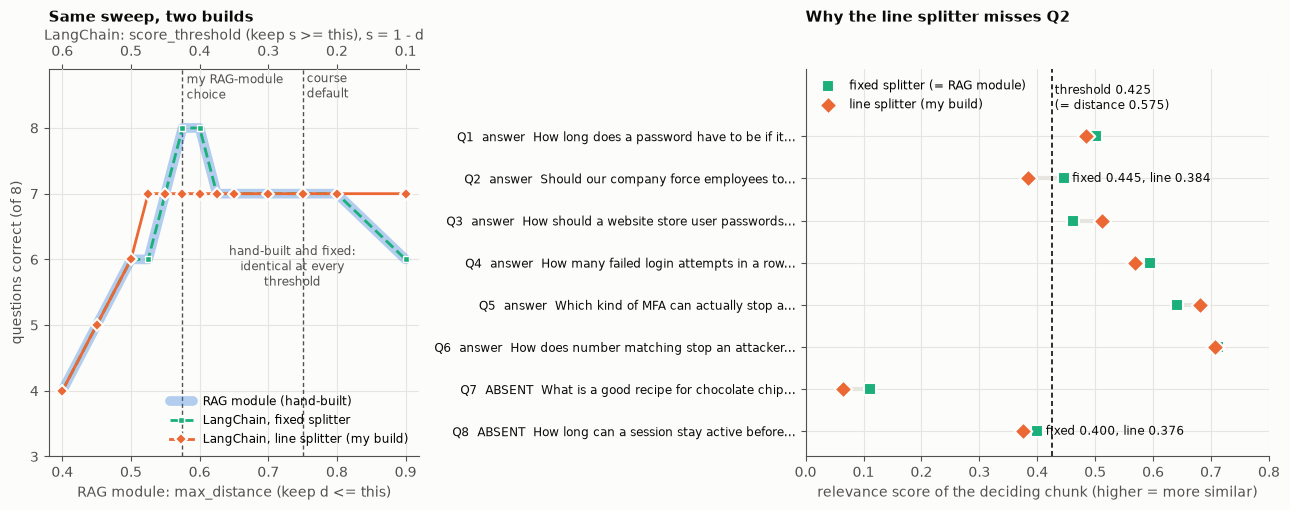

saved figure_comparison.png


In [14]:
###################  CHART  ###################
import matplotlib.pyplot as plt

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"        # validated as a set (colour-blind safe)
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": MUTED, "axes.labelcolor": MUTED,
                     "xtick.color": MUTED, "ytick.color": MUTED})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2), facecolor=SURFACE,
                               gridspec_kw={"width_ratios": [1, 1.25]})

# ---- left: the threshold sweep -------------------------------------------
d = rag_t.max_distance.values
# the hand-built and fixed-window results are identical, so the first is drawn as a wide halo under the second
ax1.plot(d, rag_t.correct_of_8.values, "-", color=BLUE, lw=7, alpha=0.35, solid_capstyle="round",
         label="RAG module (hand-built)", zorder=2)
ax1.plot(d, lc_fixed.loc[lc_line.score_threshold].correct_of_8.values, "--", color=AQUA, lw=2, marker="s", ms=5,
         markeredgecolor=SURFACE, markeredgewidth=1, label="LangChain, fixed splitter", zorder=3)
ax1.plot(d, lc_line.correct_of_8.values, "-", color=ORANGE, lw=2, marker="D", ms=6,
         markeredgecolor=SURFACE, markeredgewidth=1.5, label="LangChain, line splitter (my build)", zorder=4)
ax1.text(0.735, 5.6, "hand-built and fixed:\nidentical at every\nthreshold", fontsize=8.5, color=MUTED, ha="center")
for x, label in [(0.75, "course\ndefault"), (0.575, "my RAG-module\nchoice")]:
    ax1.axvline(x, color=MUTED, lw=1, ls=(0, (3, 2)), zorder=1)
    ax1.text(x + 0.006, 8.85, label, fontsize=8.5, color=MUTED, va="top")
ax1.set_xlim(0.38, 0.92)
ax1.set_ylim(3, 8.9)
ax1.set_xlabel("RAG module: max_distance (keep d <= this)")
ax1.set_ylabel("questions correct (of 8)")
top = ax1.secondary_xaxis("top", functions=(lambda x: 1 - x, lambda s: 1 - s))
top.set_xlabel("LangChain: score_threshold (keep s >= this), s = 1 - d")
top.tick_params(colors=MUTED)
ax1.set_title("Same sweep, two builds", loc="left", color=INK, fontsize=11, fontweight="bold", pad=34)
ax1.legend(frameon=False, fontsize=8.5, loc="lower right", bbox_to_anchor=(1.0, 0.0))

# ---- right: the score that decides each question -------------------------
def deciding_scores(db, k=8):
    out = []
    for q in MY_GOLDSET:
        top_k = db.similarity_search_with_relevance_scores(q["question"], k=k)
        if q["answerable"]:
            ev = [s for doc, s in top_k if has_evidence([doc], q["evidence"])]
            out.append(max(ev) if ev else np.nan)
        else:
            out.append(top_k[0][1])
    return np.array(out)

s_fixed = deciding_scores(store_for("fixed", 600, 100))
s_line = deciding_scores(store_for("line", 600, 100))
y = np.arange(len(MY_GOLDSET))[::-1]
for yi, a, b in zip(y, s_fixed, s_line):
    ax2.plot([a, b], [yi, yi], color=GRID, lw=3, zorder=1)
ax2.scatter(s_fixed, y, s=70, color=AQUA, marker="s", edgecolor=SURFACE, linewidth=1.5, zorder=3,
            label="fixed splitter (= RAG module)")
ax2.scatter(s_line, y, s=80, color=ORANGE, marker="D", edgecolor=SURFACE, linewidth=1.5, zorder=3,
            label="line splitter (my build)")
for yi, q, a, b in zip(y, MY_GOLDSET, s_fixed, s_line):
    if q["qid"] in ("Q2", "Q8"):
        ax2.text(max(a, b) + 0.015, yi, "fixed %.3f, line %.3f" % (a, b), va="center", fontsize=8.5, color=INK)
ax2.axvline(MY_THRESHOLD, color=INK, lw=1.2, ls=(0, (3, 2)), zorder=2)
ax2.text(MY_THRESHOLD + 0.005, len(y) - 0.45, "threshold 0.425\n(= distance 0.575)", fontsize=8.5,
         color=INK, va="bottom")
ax2.set_yticks(y)
ax2.set_yticklabels(["%s  %s  %s" % (q["qid"], "answer" if q["answerable"] else "ABSENT",
                                     textwrap.shorten(q["question"], 44, placeholder="..."))
                     for q in MY_GOLDSET], fontsize=8.5, color=INK)
ax2.set_xlim(0.0, 0.8)
ax2.set_ylim(-0.6, len(y) + 0.6)
ax2.set_xlabel("relevance score of the deciding chunk (higher = more similar)")
ax2.set_title("Why the line splitter misses Q2", loc="left", color=INK, fontsize=11, fontweight="bold", pad=34)
ax2.legend(frameon=False, fontsize=8.5, loc="upper left")

for ax in (ax1, ax2):
    ax.set_facecolor(SURFACE)
    ax.grid(color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    for side_ in ["top", "right"]:
        ax.spines[side_].set_visible(False)
plt.tight_layout()
plt.savefig("figure_comparison.png", dpi=150, facecolor=SURFACE, bbox_inches="tight")
plt.show()
print("saved figure_comparison.png")

## Part 12: One question this version got wrong: Q2

At the RAG-module settings, the LangChain bot refused **Q2** (*Should our company force employees to change their
passwords every 90 days?*), which my documents answer: NIST says verifiers SHALL NOT require periodic password
changes. The hand-built RAG found it at the same settings. The cell below shows what this version retrieved
instead, and compares the chunk that holds the answer in each build.

In [15]:
###################  ERROR ANALYSIS  ###################
def show_top(q, db, k=4, threshold=MY_THRESHOLD):
    print("%s: %s" % (q["qid"], q["question"]))
    for rank, (d, s) in enumerate(db.similarity_search_with_relevance_scores(q["question"], k=k), start=1):
        print("  #%d  score=%.3f  %-5s [%s]  evidence: %-5s  %s..."
              % (rank, s, "kept" if s >= threshold else "cut", os.path.basename(d.metadata["source"]),
                 has_evidence([d], q["evidence"]), d.page_content[:55].replace("\n", " ")))


def evidence_chunk(db, q):
    hits = [(d, s) for d, s in db.similarity_search_with_relevance_scores(q["question"], k=db._collection.count())
            if has_evidence([d], q["evidence"])]
    return hits[0]


q2 = MY_GOLDSET[1]
print("Line splitter (my build), threshold %.3f:" % MY_THRESHOLD)
show_top(q2, my_db)
print("\nFixed windows (= the RAG module), same settings:")
show_top(q2, store_for("fixed", 600, 100))

for name, db in [("LINE splitter", my_db), ("FIXED windows / hand-built", store_for("fixed", 600, 100))]:
    d, s = evidence_chunk(db, q2)
    print("\nThe chunk holding Q2's answer, %s (score %.3f, %d characters):" % (name, s, len(d.page_content)))
    print(textwrap.indent("\n".join(textwrap.fill(l, 100) for l in d.page_content.split("\n")), "    | "))

Line splitter (my build), threshold 0.425:
Q2: Should our company force employees to change their passwords every 90 days?
  #1  score=0.384  cut   [nist_password_rules.md]  evidence: True   2. Verifiers and CSPs SHOULD permit a maximum password ...
  #2  score=0.377  cut   [nist_password_blocklist_and_storage.md]  evidence: False  ## Password managers Verifiers SHALL allow the use of p...
  #3  score=0.364  cut   [cisa_number_matching.md]  evidence: False  ## The problem Cyber threat actors who have obtained a ...
  #4  score=0.347  cut   [nist_password_blocklist_and_storage.md]  evidence: False  ## Storing passwords Verifiers SHALL store passwords in...

Fixed windows (= the RAG module), same settings:
Q2: Should our company force employees to change their passwords every 90 days?
  #1  score=0.445  kept  [nist_password_rules.md]  evidence: True   types) for passwords. 6. Verifiers and CSPs SHALL NOT r...
  #2  score=0.406  cut   [nist_password_blocklist_and_storage.md]  evidence: Fa

**What happened.** The retriever ranked the right chunk first, but scored it 0.384, below the 0.425 threshold, so
it kept nothing and the branch refused. The ranking was right and the cut-off was wrong for this chunk.

**Why the score dropped.** The line splitter only cuts at line ends, so its chunk holds whole list items 2, 5, 6
and 7: a maximum length of 64 characters, no composition rules, no periodic changes, no password hints. Half of
it is about password *length and composition*, which pulls its vector away from a question about *changing*
passwords. My hand-built chunker cut at a fixed character position instead, so its window started mid-sentence at
"types) for passwords." and held items 6 to 9, which are mostly about what verifiers SHALL NOT make users do. That
chunk scored 0.445 (distance 0.555), just inside the threshold. Same text, same settings, a different chunk
boundary, and the answer moved from one side of the threshold to the other.

**Why tuning does not really fix it.** For the line splitter, Q2's evidence scores 0.384 and Q8's best chunk scores
0.376 (Part 10, `weakest_answer_score` and `strongest_trap_score`). An 8/8 threshold exists, but only between
0.376 and 0.384: a window of 0.008, against 0.045 for the hand-built chunks. Any new question would almost
certainly land on the wrong side of it. And at the course default (score 0.25) the opposite failure returns: Q8
is answered from the rate-limiting chunk, exactly as in the RAG module.

In [16]:
# The opposite failure, at the course default (score 0.25 = distance 0.75): Q8 is not in my documents.
q8 = MY_GOLDSET[7]
loose = build_chain(my_db.as_retriever(search_type="similarity_score_threshold",
                                       search_kwargs={"k": MY_K, "score_threshold": 0.25}))
show(q8, loose.invoke(q8["question"]), my_db, MY_K, 0.25)

Q8  How long can a session stay active before NIST requires the user to reauthenticate?
    expected: NOT in my documents, so it should be refused
    retrieved  score=0.376  [nist_rate_limiting_and_aal.md]  # NIST SP 800-63B-4: Rate Limiting (Section 3.2.2)...
    retrieved  score=0.369  [nist_rate_limiting_and_aal.md]  - Requiring the claimant to wait after a failed at...
    retrieved  score=0.303  [cisa_number_matching.md]  ## The problem Cyber threat actors who have obtain...
    retrieved  score=0.280  [nist_rate_limiting_and_aal.md]  The limit of 100 attempts is an upper bound, and a...
    answer:    [RAG] (offline) Unless otherwise specified in the description of a given authenticator, the verifier
               SHALL limit consecutive failed authentication attempts using a specific authenticator on a
               single subscriber account to no more than 100 by disabling that authenticator.
               [nist_rate_limiting_and_aal.md] Requiring the claimant to wait after

### What the framework hides

The rebuild was shorter, but four things I could see in my own code are now inside LangChain, and three of them
changed my numbers. The cell below shows each one.

1. **Where chunks end.** `chunk_size` is a target, not a limit: a line longer than 600 characters becomes one
   over-size chunk. And the boundaries are chosen by the separator, which is how Q2 was lost.
2. **How the score is computed.** It depends on the store's distance metric, which I never see unless I ask
   (8.4). With the default metric my threshold of 0.425 would mean a distance of 0.407, much stricter than 0.575.
3. **Which collection the vectors go into.** `from_documents()` without a `collection_name` appends to a shared
   in-memory collection, so re-running a cell silently duplicates every chunk.
4. **What a "chunk" can be.** The line splitter only joins whole lines, so when the next paragraph does not fit,
   a title and a heading become a chunk on their own (81 and 94 characters in the two CISA files). Such a chunk
   says nothing, but it is short and on-topic, so it is the best match for Q5 (0.737). With the line splitter the
   answer is still 3rd; `RecursiveCharacterTextSplitter` makes the same heading chunk and also cuts the long
   paragraph at spaces, which pushes the answer out of the top 4.

In [17]:
# 1. Where chunks end: chunk_size is not a cap
big = [c for c in my_chunks if len(c.page_content) > CHUNK_SIZE]
print("1. chunks longer than chunk_size=%d with the line splitter: %d" % (CHUNK_SIZE, len(big)))
for c in big:
    print("   %d characters from %s: %s..." % (len(c.page_content), os.path.basename(c.metadata["source"]),
                                               c.page_content[:80]))
fixed_first = SPLITTERS["fixed"](600, 100).split_documents(my_docs[3:4])     # nist_password_rules.md
line_first = SPLITTERS["line"](600, 100).split_documents(my_docs[3:4])
print("   first chunk boundary in nist_password_rules.md:  fixed ends ...%r   line ends ...%r"
      % (fixed_first[0].page_content[-30:], line_first[0].page_content[-30:]))

# 2. How the score is computed: the default store's metric and formula
print("\n2. metric of a store built with no configuration: %s, so score = 1 - d_L2^2 / sqrt(2) = 1 - sqrt(2) * d_cos"
      % default_db._collection.configuration["hnsw"]["space"])
m = results_lc[(results_lc.experiment == "metric")]
print(m[["metric", "score_threshold", "equivalent_max_distance", "found", "refused", "missed", "not_refused"]]
      .to_string(index=False))

# 3. Which collection: building the same store twice without a fresh name
demo1 = Chroma.from_documents(my_chunks, embeddings, collection_name="rerun_demo", collection_configuration=COSINE)
n1 = demo1._collection.count()
demo2 = Chroma.from_documents(my_chunks, embeddings, collection_name="rerun_demo", collection_configuration=COSINE)
top4 = [d.page_content[:40] for d in demo2.similarity_search(MY_GOLDSET[3]["question"], k=4)]
print("\n3. same collection built twice: %d chunks, then %d; Q4's top 4 has %d distinct chunks"
      % (n1, demo2._collection.count(), len(set(top4))))

# 4. What a chunk can be: a heading on its own
tiny = [c for c in my_chunks if len(c.page_content) < 100]
print("\n4. line-splitter chunks under 100 characters: %d" % len(tiny))
for c in tiny:
    print("   %d characters from %s: %r" % (len(c.page_content), os.path.basename(c.metadata["source"]), c.page_content))
print("\n   Line splitter (my build):")
show_top(MY_GOLDSET[4], my_db)
print("\n   RecursiveCharacterTextSplitter(600, 100):")
show_top(MY_GOLDSET[4], store_for("recursive", 600, 100))

1. chunks longer than chunk_size=600 with the line splitter: 1
   800 characters from cisa_phishing_resistant_mfa.md: MFA is a security control that requires a user to present a combination of two o...
   first chunk boundary in nist_password_rules.md:  fixed ends ...'iber or assigned randomly by t'   line ends ...'sword Authenticators (3.1.1.1)'

2. metric of a store built with no configuration: l2, so score = 1 - d_L2^2 / sqrt(2) = 1 - sqrt(2) * d_cos
metric  score_threshold  equivalent_max_distance  found  refused      missed not_refused
cosine            0.250                    0.750      6        1                      Q8
    l2            0.250                    0.530      5        2          Q2            
cosine            0.425                    0.575      5        2          Q2            
    l2            0.425                    0.407      2        2 Q1 Q2 Q3 Q4            



3. same collection built twice: 27 chunks, then 54; Q4's top 4 has 2 distinct chunks

4. line-splitter chunks under 100 characters: 2
   94 characters from cisa_number_matching.md: '# CISA Fact Sheet: Implementing Number Matching in MFA Applications (October 2022)\n## Overview'
   81 characters from cisa_phishing_resistant_mfa.md: '# CISA Fact Sheet: Implementing Phishing-Resistant MFA (October 2022)\n## Overview'

   Line splitter (my build):
Q5: Which kind of MFA can actually stop a phishing attack?
  #1  score=0.737  kept  [cisa_phishing_resistant_mfa.md]  evidence: False  # CISA Fact Sheet: Implementing Phishing-Resistant MFA ...
  #2  score=0.693  kept  [cisa_phishing_resistant_mfa.md]  evidence: False  MFA is a security control that requires a user to prese...
  #3  score=0.680  kept  [cisa_phishing_resistant_mfa.md]  evidence: True   4. SMS or Voice. Vulnerable to phishing, SS7, and SIM s...
  #4  score=0.654  kept  [cisa_phishing_resistant_mfa.md]  evidence: False  ## MFA form

## Summary

| Configuration (chunk / overlap / k / threshold) | Found | Refused | Wrong |
|---|---|---|---|
| RAG module, course defaults (600 / 100 / 4 / d ≤ 0.75) | 6/6 | 1/2 | Q8 answered |
| RAG module, my settings (600 / 100 / 4 / d ≤ 0.575) | 6/6 | 2/2 | none |
| LangChain, line splitter (600 / 100 / 4 / s ≥ 0.25) | 6/6 | 1/2 | Q8 answered |
| **LangChain, line splitter (600 / 100 / 4 / s ≥ 0.425), like for like** | **5/6** | **2/2** | **Q2 refused** |
| LangChain, fixed splitter (600 / 100 / 4 / s ≥ 0.425) | 6/6 | 2/2 | none |

- **The flip is exact.** In a cosine store LangChain's relevance score is 1 − distance, so "keep d ≤ 0.575"
  became "keep s ≥ 0.425". Getting the direction backwards (s ≤ 0.425) would keep the *worst* chunks.
- **LangChain reproduces the hand-built RAG** when it cuts the same chunks: with fixed windows, all 33 RAG-module
  configurations give the same found and refused counts and fail on the same questions.
- **The difference is the splitter.** The lecture's line splitter makes cleaner chunks, but at my threshold it
  loses Q2, and its safe window shrinks from 0.045 to 0.008.
- **Results:** `results_langchain.csv` (configurations, with the like-for-like rows flagged), `figure_comparison.png`.

**What my evidence does not tell me.** Eight questions are very few, and the threshold was chosen on the same
eight questions in the RAG module. A difference of one question, like Q2 here, can come from where a single
chunk boundary fell. The score also measures retrieval, not answers. Q1 counts as found, and the 15-character
rule is in the first chunk retrieved, but the offline stand-in's three sentences skip it (in the RAG module its
answer quoted the rule third): with line-aligned chunks, other sentences ranked higher. A real model reads the whole
chunk, but it could still answer badly from the right one.